Read data and create Train/Test split

In [62]:
#Loading the clean data
import pandas as pd

books = pd.read_csv("../data/clean/books_clean.csv")
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   book_id      175 non-null    int64  
 1   upc          175 non-null    str    
 2   title        175 non-null    str    
 3   category     175 non-null    str    
 4   description  174 non-null    str    
 5   lang         175 non-null    str    
 6   image_path   175 non-null    str    
 7   price        175 non-null    float64
 8   rating       175 non-null    int64  
 9   product_url  175 non-null    str    
dtypes: float64(1), int64(2), str(7)
memory usage: 13.8 KB


In [63]:
#Split the data into train and test
from sklearn.model_selection import train_test_split
train_ids, test_ids = train_test_split(books["book_id"], test_size=0.2, random_state=42, stratify=books["category"])
print("Train:", len(train_ids))
print("Test:", len(test_ids))

Train: 140
Test: 35


In [64]:
#Save the train/split data into a file
split_df = pd.DataFrame({"book_id": books["book_id"]})

split_df["split"] = "train"

split_df.loc[split_df["book_id"].isin(test_ids), "split"] = "test"
split_df.to_csv("../data/features/split.csv",index=False)

display(split_df.head())

,book_id,split
0,998,train
1,958,train
2,954,train
3,946,train
4,939,train


Model Training

In [65]:
#Read "features" and "split" file
features = pd.read_csv("../data/features/features_word_counts.csv")
split = pd.read_csv("../data/features/split.csv")

print(features.shape)
print(split.shape)

(175, 2116)
(175, 2)


In [66]:
#Merge features with train/test split data 
df = features.merge(books[["book_id", "category"]], on="book_id", validate="one_to_one").merge(split, on="book_id", validate="one_to_one")

print(df.shape)
display(df[["book_id", "category", "split"]].head())

(175, 2118)


,book_id,category,split
0,998,Fiction,train
1,958,Fiction,train
2,954,Fiction,train
3,946,Fiction,train
4,939,Fiction,train


In [67]:
#Create x_train, x_test, y_train, y_test
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

feature_columns = features.columns.drop("book_id")

X_train = train[feature_columns]
X_test = test[feature_columns]

y_train = train["category"]
y_test = test["category"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (140, 2115)
X_test: (35, 2115)
y_train: (140,)
y_test: (35,)


In [68]:
#Multinominal Naive Bayes
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

NB = MultinomialNB()
NB.fit(X_train, y_train)

Y_Pred_NB = NB.predict(X_test)

print("Accuracy:", accuracy_score(y_test, Y_Pred_NB))
print(confusion_matrix(y_test, Y_Pred_NB))
print(classification_report(y_test, Y_Pred_NB))

Accuracy: 0.8571428571428571
[[11  2]
 [ 3 19]]
              precision    recall  f1-score   support

     Fiction       0.79      0.85      0.81        13
  Nonfiction       0.90      0.86      0.88        22

    accuracy                           0.86        35
   macro avg       0.85      0.85      0.85        35
weighted avg       0.86      0.86      0.86        35



In [69]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression

LR = LogisticRegression(max_iter=1000)

LR.fit(X_train, y_train)

Y_Pred_LR = LR.predict(X_test)

print("Accuracy:", accuracy_score(y_test, Y_Pred_LR))
print(confusion_matrix(y_test, Y_Pred_LR))
print(classification_report(y_test, Y_Pred_LR))

Accuracy: 0.8
[[ 7  6]
 [ 1 21]]
              precision    recall  f1-score   support

     Fiction       0.88      0.54      0.67        13
  Nonfiction       0.78      0.95      0.86        22

    accuracy                           0.80        35
   macro avg       0.83      0.75      0.76        35
weighted avg       0.81      0.80      0.79        35



In [70]:
#Read TF-IDF
tfidf = pd.read_csv("../data/features/features_tfidf.csv")

df_tfidf = tfidf.merge(books[["book_id", "category"]], on="book_id", validate="one_to_one").merge(split, on="book_id", validate="one_to_one")

print(tfidf.shape)
display(tfidf.head())

(175, 2116)


,book_id,000,10,100,11,13,1942,1945,1950s,1955,...,wrote,wry,year,years,yes,york,young,younger,youngest,youth
0,998,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1,958,0.0,0.090247,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.054418,0.0,0.0,0.0
2,954,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.08613,0.0,0.0,0.0,0.077598,0.0,0.0,0.0
3,946,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,939,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [71]:
#Create x_train, x_test, y_train, y_test for TF-IDF
train_tfidf = df_tfidf[df_tfidf["split"] == "train"]
test_tfidf = df_tfidf[df_tfidf["split"] == "test"]

feature_columns_tfidf = tfidf.columns.drop("book_id")

X_train_tfidf = train_tfidf[feature_columns_tfidf]
X_test_tfidf = test_tfidf[feature_columns_tfidf]

y_train_tfidf = train_tfidf["category"]
y_test_tfidf = test_tfidf["category"]

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(140, 2115)
(35, 2115)


In [72]:
#Logistic Regression with TF-IDF
LR_tfidf = LogisticRegression(max_iter=1000)

LR_tfidf.fit(X_train_tfidf, y_train_tfidf)

Y_Pred_LR_tfidf = LR_tfidf.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test_tfidf, Y_Pred_LR_tfidf))

print(confusion_matrix(y_test_tfidf, Y_Pred_LR_tfidf))

print(classification_report(y_test_tfidf, Y_Pred_LR_tfidf))

Accuracy: 0.6571428571428571
[[ 1 12]
 [ 0 22]]
              precision    recall  f1-score   support

     Fiction       1.00      0.08      0.14        13
  Nonfiction       0.65      1.00      0.79        22

    accuracy                           0.66        35
   macro avg       0.82      0.54      0.46        35
weighted avg       0.78      0.66      0.55        35



In [73]:
#Prepare image features
images = pd.read_csv("../data/features/features_images.csv")

#Merge images features with train/test split data
df_images = images.merge(books[["book_id", "category"]], on="book_id", validate="one_to_one").merge(split, on="book_id", validate="one_to_one")
image_columns = images.columns.drop("book_id")

train_images = df_images[df_images["split"] == "train"]
test_images = df_images[df_images["split"] == "test"]

X_train_images = train_images[image_columns]
X_test_images = test_images[image_columns]

y_train_images = train_images["category"]
y_test_images = test_images["category"]

print("X_train_images:", X_train_images.shape)
print("X_test_images:", X_test_images.shape)


X_train_images: (140, 30)
X_test_images: (35, 30)


In [74]:
# Logistic Regression with Images Only
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

LR_image = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

LR_image.fit(X_train_images, y_train_images)

Y_Pred_images = LR_image.predict(X_test_images)

print("Accuracy:", accuracy_score(y_test_images, Y_Pred_images))
print(confusion_matrix(y_test_images, Y_Pred_images))
print(classification_report(y_test_images, Y_Pred_images))

Accuracy: 0.6285714285714286
[[ 4  9]
 [ 4 18]]
              precision    recall  f1-score   support

     Fiction       0.50      0.31      0.38        13
  Nonfiction       0.67      0.82      0.73        22

    accuracy                           0.63        35
   macro avg       0.58      0.56      0.56        35
weighted avg       0.60      0.63      0.60        35



In [75]:
#Cross-Validation for images
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

image_scores = cross_val_score(
    LR_image,
    X_train_images,
    y_train_images,
    cv=cv,
    scoring="f1_macro"
)

print("Images Only - CV Macro F1:", image_scores.mean())
print("Fold scores:", image_scores)

Images Only - CV Macro F1: 0.5425307447982102
Fold scores: [0.475      0.56187767 0.45098039 0.52042161 0.70437406]


In [76]:
# Cross-validation for the four models
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

#Prepare data
cv_data = books.merge(split, on="book_id", validate="one_to_one")

cv_data["text"] = (cv_data["title"].fillna("") + " " + cv_data["description"].fillna(""))

train_cv = cv_data[cv_data["split"] == "train"]

X_text_cv = train_cv["text"]
y_text_cv = train_cv["category"]

#Add four models to compare
text_models = {
    "NB + Word Counts": make_pipeline(
        CountVectorizer(stop_words="english", min_df=2),
        MultinomialNB()
    ),

    "LR + Word Counts": make_pipeline(
        CountVectorizer(stop_words="english", min_df=2),
        LogisticRegression(max_iter=1000)
    ),

    "LR + TF-IDF": make_pipeline(
        TfidfVectorizer(stop_words="english", min_df=2),
        LogisticRegression(max_iter=1000)
    ),

    "LR + TF-IDF Balanced": make_pipeline(
        TfidfVectorizer(stop_words="english", min_df=2),
        LogisticRegression(max_iter=1000, class_weight="balanced")
    )
}

#Run Cross-Validation
cv_results = []

for name, model in text_models.items():
    scores = cross_val_score(
        model,
        X_text_cv,
        y_text_cv,
        cv=cv,
        scoring="f1_macro"
    )

    cv_results.append({"Model": name, "CV Macro F1": scores.mean()})

#Add LR with images results
cv_results.append({"Model": "LR + Images Only", "CV Macro F1": image_scores.mean()})

cv_comparison = pd.DataFrame(cv_results)
display(cv_comparison.sort_values("CV Macro F1", ascending=False).round(3))

,Model,CV Macro F1
0,NB + Word Counts,0.812
3,LR + TF-IDF Balanced,0.812
1,LR + Word Counts,0.794
4,LR + Images Only,0.543
2,LR + TF-IDF,0.406


In [77]:
#Logistic Regression Text + Images
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

combined_cv_data = train_cv[["book_id", "text", "category"]].merge(images, on="book_id", validate="one_to_one")

image_cols = images.columns.drop("book_id").tolist()

X_combined_cv = combined_cv_data[["text"] + image_cols]
y_combined_cv = combined_cv_data["category"]

combined_preprocessor = ColumnTransformer([
    (
        "text",
        CountVectorizer(stop_words="english", min_df=2),
        "text"
    ),
    (
        "image",
        StandardScaler(),
        image_cols
    )
])

combined_cv_model = Pipeline([("preprocessor", combined_preprocessor), ("classifier", LogisticRegression(max_iter=1000))])

combined_cv_scores = cross_val_score(
    combined_cv_model,
    X_combined_cv,
    y_combined_cv,
    cv=cv,
    scoring="f1_macro"
)

print("Corrected Text + Images CV Macro F1:",
      round(combined_cv_scores.mean(), 4))


Corrected Text + Images CV Macro F1: 0.7094


In [78]:
#Add Text + Images model to cross validation comparison and save it into a file
cv_results.append({"Model": "LR + Word Counts + Images", "CV Macro F1": combined_cv_scores.mean()})

cv_comparison = pd.DataFrame(cv_results).sort_values("CV Macro F1", ascending=False).reset_index(drop=True)

display(cv_comparison.round(4))
cv_comparison.to_csv("../results/cv_comparison.csv", index=False)

,Model,CV Macro F1
0,NB + Word Counts,0.8123
1,LR + TF-IDF Balanced,0.8117
2,LR + Word Counts,0.7940
3,LR + Word Counts + Images,0.7094
4,LR + Images Only,0.5425
5,LR + TF-IDF,0.4058


Final Model (Naive Bayes + Word Counts) Evaluation and Model Comparison 

In [79]:
#Calculate the statistics of the final model
from sklearn.metrics import f1_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay

final_predictions = NB.predict(X_test)

print("Final Model: MultinomialNB + Word Counts")
print("Test Accuracy:", round(accuracy_score(y_test, final_predictions), 4))
print("Test Macro F1:", round(f1_score(y_test, final_predictions, average="macro"), 4))
print("Test Balanced Accuracy:", round(balanced_accuracy_score(y_test, final_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

Final Model: MultinomialNB + Word Counts
Test Accuracy: 0.8571
Test Macro F1: 0.8493
Test Balanced Accuracy: 0.8549

Classification Report:
              precision    recall  f1-score   support

     Fiction       0.79      0.85      0.81        13
  Nonfiction       0.90      0.86      0.88        22

    accuracy                           0.86        35
   macro avg       0.85      0.85      0.85        35
weighted avg       0.86      0.86      0.86        35



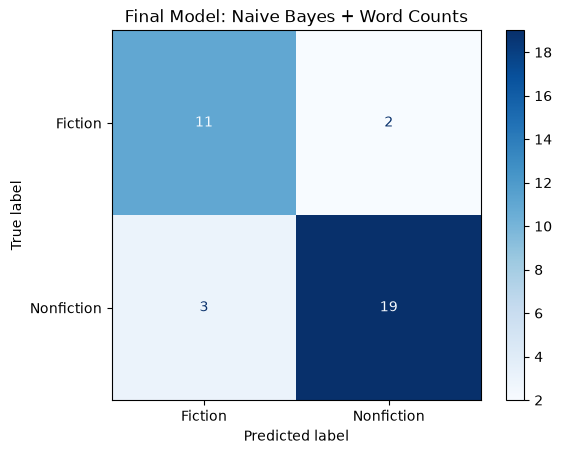

In [80]:
# Create confusion matrix and save in a file
import matplotlib.pyplot as plt
labels = ["Fiction", "Nonfiction"]

cm = confusion_matrix(y_test, final_predictions, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Final Model: Naive Bayes + Word Counts")
plt.savefig("../results/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#Compare models according to a baseline
from sklearn.metrics import recall_score

Y_Pred_baseline = ["Nonfiction"] * len(y_test)

model_predictions = [("MultinomialNB + Word Counts", y_test, Y_Pred_NB), ("Logistic Regression + Word Counts", y_test, Y_Pred_LR), 
                     ("Logistic Regression + TF-IDF", y_test_tfidf, Y_Pred_LR_tfidf), ("Always Nonfiction (Baseline)", y_test, Y_Pred_baseline)]

results = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Macro F1": f1_score(actual, predicted, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(actual, predicted),
        "Fiction Recall": recall_score(
            actual,
            predicted,
            pos_label="Fiction"
        )
    }
    for name, actual, predicted in model_predictions
])

display(results.round(4))

#Save the result into a file
results.to_csv(
    "../results/model_comparison.csv",
    index=False
)


,Model,Accuracy,Macro F1,Balanced Accuracy,Fiction Recall
0,MultinomialNB + Word Counts,0.8571,0.8493,0.8549,0.8462
1,Logistic Regression + Word Counts,0.8000,0.7619,0.7465,0.5385
2,Logistic Regression + TF-IDF,0.6571,0.4643,0.5385,0.0769
3,Always Nonfiction (Baseline),0.6286,0.3860,0.5000,0.0000
